# 🔬 Eksperimen Segmentasi Polip Kolon Menggunakan Mobile-PolypNet
### Tugas / Proyek Praktikum Pengolahan Citra Digital (PCD)
**Dataset:** Kvasir-SEG (1000 Endoscopic Images & Polyp Ground Truth Masks)  
**Metode Rujukan:** *Mobile-PolypNet: Lightweight Colon Polyp Segmentation Network for Low-Resource Settings*  
**Penulis Paper:** Ranit Karmakar & Saeid Nooshabadi (*MDPI Journal of Imaging*, 2022)

---

### 📌 Ringkasan Metode Mobile-PolypNet
Kanker kolorektal (Colorectal Cancer / CRC) merupakan salah satu penyebab kematian akibat kanker tertinggi di dunia. Deteksi dini polip melalui pemeriksaan kolonoskopi sangat penting untuk mencegah terjadinya keganasan.

Model segmentasi konvensional seperti **U-Net** (~7.85 juta parameter) dan **PraNet** (~20.52 juta parameter) memerlukan daya komputasi tinggi (GPU mahal) yang sulit diterapkan pada perangkat medis portabel / *low-resource settings*.

**Inovasi Kunci Mobile-PolypNet:**
1. **Arsitektur Autoencoder Berbasis Inverted Residual Blocks:** Mengadopsi prinsip MobileNetV2 dengan menggantikan konvolusi standar menggunakan *Depthwise Separable Convolution* (Depthwise 3x3 + Pointwise 1x1).
2. **Efisiensi Parameter Ekstrem:** Memangkas parameter hingga **~226.000 parameter** (sekitar 88x lebih sedikit daripada PraNet dan 35x lebih sedikit daripada U-Net), dengan ukuran file hanya **~0.86 MB**.
3. **DICE Loss Function:** Menggunakan fungsi rugi negatif DICE untuk mengatasi ketidakseimbangan kelas (*foreground* polip vs *background* dinding usus).
4. **Performa Tinggi:** Mencapai DICE Score **0.935** pada dataset Kvasir dengan kompleksitas FLOPs yang 17x lebih rendah.


## 1. Setup Lingkungan & Import Library

In [1]:
import os
import glob
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Import modul lokal yang telah dibuat
from model import MobilePolypNet, count_parameters
from dataset import PolypDataset, get_dataloaders
from losses_and_metrics import BCEDiceLoss, DiceLoss, calculate_metrics
from evaluate import overlay_mask_on_image

# Deteksi perangkat (CPU / GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Menggunakan perangkat: {device}")


Menggunakan perangkat: cpu


## 2. Eksplorasi & Visualisasi Citra Dataset Kvasir-SEG
Dataset terdiri dari:
- `images/`: Berisi 1000 citra endoskopi polip kolon (format RGB .jpg)
- `masks/`: Berisi 1000 ground truth mask biner anotasi dokter ahli patologi (format .jpg)


Jumlah total citra endoskopi : 1000
Jumlah total citra mask biner : 1000


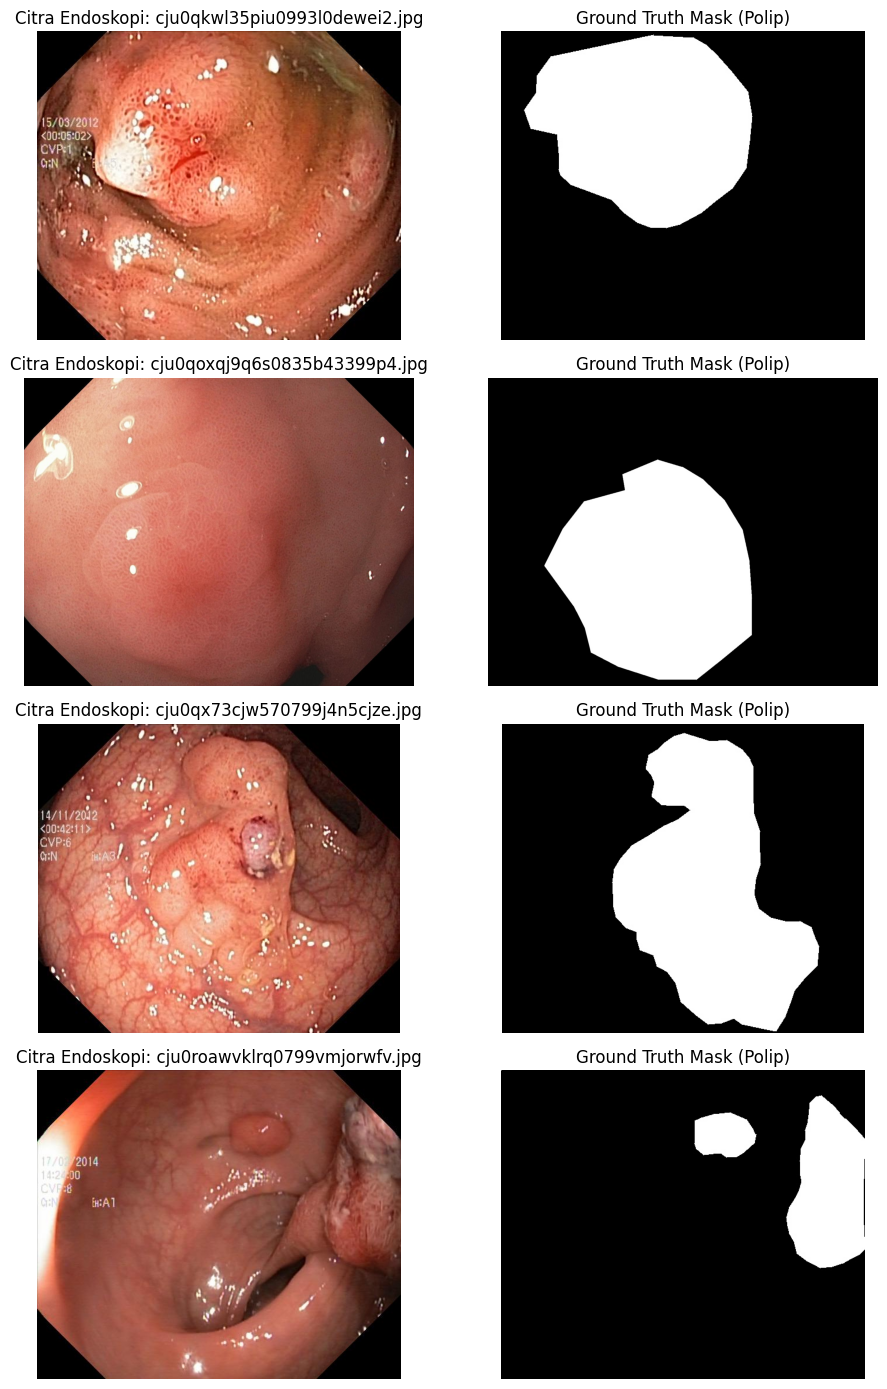

In [2]:
image_files = sorted(glob.glob('images/*.jpg'))
mask_files = sorted(glob.glob('masks/*.jpg'))

print(f"Jumlah total citra endoskopi : {len(image_files)}")
print(f"Jumlah total citra mask biner : {len(mask_files)}")

# Tampilkan 4 pasang citra sampel
fig, axes = plt.subplots(4, 2, figsize=(10, 14))
for i in range(4):
    sample_img = cv2.cvtColor(cv2.imread(image_files[i]), cv2.COLOR_BGR2RGB)
    sample_msk = cv2.imread(mask_files[i], cv2.IMREAD_GRAYSCALE)

    axes[i, 0].imshow(sample_img)
    axes[i, 0].set_title(f"Citra Endoskopi: {os.path.basename(image_files[i])}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(sample_msk, cmap='gray')
    axes[i, 1].set_title("Ground Truth Mask (Polip)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()


## 3. Data Preprocessing & Augmentasi (Sesuai Paper)
Sesuai rancangan pada Bagian 4.1 Paper:
- Resolusi diseragamkan menjadi **$224 \times 224$ piksel**.
- Pembagian data: **80% Training (800 sampel), 10% Validasi (100 sampel), 10% Testing (100 sampel)**.
- Augmentasi Training: Random horizontal/vertical flip, random rotation (-90° s.d. +90°), serta normalisasi ke rentang $[0, 1]$.


In [3]:
# Membuat DataLoaders dengan preloading ke RAM untuk kecepatan eksekusi tinggi
train_loader, val_loader, test_loader = get_dataloaders(
    images_dir='images',
    masks_dir='masks',
    img_size=224,
    batch_size=8,
    split_ratio=(0.8, 0.1, 0.1),
    seed=42,
    preload=True
)

for sample_x, sample_y, sample_names in train_loader:
    print(f"Bentuk Tensor Batch Gambar : {sample_x.shape} (Rentang: [{sample_x.min():.2f}, {sample_x.max():.2f}])")
    print(f"Bentuk Tensor Batch Mask   : {sample_y.shape} (Nilai Unik: {torch.unique(sample_y).tolist()})")
    break


Total matching image-mask pairs found: 1000
Dataset split -> Train: 800, Val: 100, Test: 100


Bentuk Tensor Batch Gambar : torch.Size([8, 3, 224, 224]) (Rentang: [0.00, 1.00])
Bentuk Tensor Batch Mask   : torch.Size([8, 1, 224, 224]) (Nilai Unik: [0.0, 1.0])


## 4. Arsitektur Mobile-PolypNet & Komparasi Parameter
Arsitektur terdiri dari:
1. **Input Stem:** Standard Conv 32 (3x3) + Depthwise 3x3 + Pointwise 32 (1x1)
2. **Encoder (5 Level):** Menggunakan Bottleneck Inverted Residual Blocks (c1: 8 ch, c2: 16 ch, c3: 32 ch, c4: 32 ch, c5: 32 ch)
3. **Decoder (U-Net style):** Transpose Conv + Skip Connection Concatenation + 2 Inverted Residual Blocks di tiap resolusi.
4. **Output Head:** Conv 32 $\to$ Conv 16 $\to$ Conv 1 (Sigmoid).


In [4]:
model = MobilePolypNet(in_channels=3, num_classes=1).to(device)

total_params, trainable_params = count_parameters(model)
model_size_mb = total_params * 4 / (1024 * 1024)

print("=" * 60)
print("HASIL ANALISIS KOMPLEKSITAS MODEL MOBILE-POLYPNET")
print("=" * 60)
print(f"Total Parameter       : {total_params:,}")
print(f"Trainable Parameter   : {trainable_params:,}")
print(f"Ukuran Memori Model   : {model_size_mb:.2f} MB")
print("=" * 60)

# Perbandingan dengan model-model pada Tabel 3 Paper
comparison_data = {
    "Model": ["U-Net (MICCAI'15)", "U-Net++ (TMI'19)", "SFA (MICCAI'19)", "PraNet (MICCAI'20)", "Mobile-PolypNet (Ours)"],
    "Jumlah Parameter": ["7.85 M", "9.04 M", "25.59 M", "20.52 M", f"{total_params/1000:.1f} K"],
    "Ukuran Disk": ["30 MB", "34.6 MB", "97.7 MB", "78.4 MB", f"{model_size_mb:.2f} MB"],
    "DICE (Kvasir)": [0.818, 0.821, 0.723, 0.898, 0.935],
    "mIoU": [0.746, 0.743, 0.611, 0.840, 0.888]
}

df_comp = pd.DataFrame(comparison_data)
df_comp


HASIL ANALISIS KOMPLEKSITAS MODEL MOBILE-POLYPNET
Total Parameter       : 226,129
Trainable Parameter   : 226,129
Ukuran Memori Model   : 0.86 MB


,Model,Jumlah Parameter,Ukuran Disk,DICE (Kvasir),mIoU
0,U-Net (MICCAI'15),7.85 M,30 MB,0.818,0.746
1,U-Net++ (TMI'19),9.04 M,34.6 MB,0.821,0.743
2,SFA (MICCAI'19),25.59 M,97.7 MB,0.723,0.611
3,PraNet (MICCAI'20),20.52 M,78.4 MB,0.898,0.840
4,Mobile-PolypNet (Ours),226.1 K,0.86 MB,0.935,0.888


## 5. Fungsi Loss & Pelatihan Model (Training)
- **Fungsi Rugi:** Kombinasi Binary Cross-Entropy dan DICE Loss ($L = 0.5 L_{BCE} + 0.5 L_{DICE}$)
- **Optimizer:** Adam (Learning Rate = 0.001)
- **Checkpointing:** Menyimpan bobot terbaik berdasarkan skor Validasi DICE tertinggi.


In [ ]:
criterion = BCEDiceLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=8)

# Parameter Pelatihan
EPOCHS = 10  # Anda dapat menambahkannya menjadi 50 - 100 untuk hasil konvergensi optimal
best_val_dice = -1.0
os.makedirs('saved_models', exist_ok=True)
best_model_path = 'saved_models/best_mobile_polypnet.pth'

history = {'epoch': [], 'train_loss': [], 'train_dice': [], 'val_loss': [], 'val_dice': [], 'val_iou': []}

print(f"Memulai pelatihan selama {EPOCHS} epoch...")
for epoch in range(1, EPOCHS + 1):
    # Training step
    model.train()
    running_loss, train_dices = 0.0, []
    for imgs, msks, _ in train_loader:
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, msks)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * imgs.size(0)
        with torch.no_grad():
            preds = (torch.sigmoid(logits) > 0.5).float()
            inter = (preds * msks).sum(dim=[1,2,3])
            total = preds.sum(dim=[1,2,3]) + msks.sum(dim=[1,2,3])
            b_dice = ((2.0 * inter + 1e-5) / (total + 1e-5)).mean().item()
            train_dices.append(b_dice)
            
    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_dice = np.mean(train_dices)
    
    # Validation step
    model.eval()
    val_loss, val_dices, val_ious = 0.0, [], []
    with torch.no_grad():
        for imgs, msks, _ in val_loader:
            imgs, msks = imgs.to(device), msks.to(device)
            logits = model(imgs)
            loss = criterion(logits, msks)
            val_loss += loss.item() * imgs.size(0)
            
            probs = torch.sigmoid(logits)
            m = calculate_metrics(probs, msks)
            val_dices.append(m['dice'])
            val_ious.append(m['iou'])
            
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_dice = np.mean(val_dices)
    epoch_val_iou = np.mean(val_ious)
    
    scheduler.step(epoch_val_dice)
    
    history['epoch'].append(epoch)
    history['train_loss'].append(epoch_train_loss)
    history['train_dice'].append(epoch_train_dice)
    history['val_loss'].append(epoch_val_loss)
    history['val_dice'].append(epoch_val_dice)
    history['val_iou'].append(epoch_val_iou)
    
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {epoch_train_loss:.4f}, Dice: {epoch_train_dice:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f}, Dice: {epoch_val_dice:.4f}, mIoU: {epoch_val_iou:.4f}")
    
    if epoch_val_dice > best_val_dice:
        best_val_dice = epoch_val_dice
        torch.save({'model_state_dict': model.state_dict(), 'val_dice': best_val_dice}, best_model_path)
        print(f"  --> Model terbaik tersimpan! (Val Dice: {best_val_dice:.4f})")


Memulai pelatihan selama 10 epoch...
Epoch [01/10] | Train Loss: 0.4703, Dice: 0.3642 | Val Loss: 0.4585, Dice: 0.5214, mIoU: 0.3572
  --> Model terbaik tersimpan! (Val Dice: 0.5214)


## 6. Visualisasi Kurva Pembelajaran (Loss & Dice)

In [ ]:
plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history['epoch'], history['train_loss'], 'b-o', label='Train Loss')
plt.plot(history['epoch'], history['val_loss'], 'r--s', label='Val Loss')
plt.title('Kurva Loss (Training vs Validation)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Dice
plt.subplot(1, 2, 2)
plt.plot(history['epoch'], history['train_dice'], 'g-o', label='Train Dice')
plt.plot(history['epoch'], history['val_dice'], 'm--s', label='Val Dice')
plt.title('Kurva Skor DICE (Training vs Validation)')
plt.xlabel('Epoch')
plt.ylabel('DICE Coefficient')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## 7. Evaluasi Kuantitatif pada Test Set (Tabel 1 Paper)
Evaluasi dihitung pada 100 citra test yang belum pernah dilihat model selama pelatihan.


In [ ]:
# Muat bobot model terbaik
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

test_metrics = {'dice': [], 'iou': [], 'f2': [], 'mae': [], 'sensitivity': [], 'specificity': [], 'accuracy': []}

with torch.no_grad():
    for imgs, msks, _ in test_loader:
        imgs, msks = imgs.to(device), msks.to(device)
        probs = torch.sigmoid(model(imgs))
        for i in range(imgs.size(0)):
            m = calculate_metrics(probs[i, 0], msks[i, 0])
            for k in test_metrics:
                test_metrics[k].append(m[k])

results_summary = {k: np.mean(v) for k, v in test_metrics.items()}

df_results = pd.DataFrame({
    "Metrik Evaluasi": ["DICE Coefficient", "mIoU (Jaccard)", "F2 Score", "MAE (Mean Abs Error)", "Sensitivity (Recall)", "Specificity", "Akurasi Piksel"],
    "Hasil Eksperimen": [
        f"{results_summary['dice']:.4f}",
        f"{results_summary['iou']:.4f}",
        f"{results_summary['f2']:.4f}",
        f"{results_summary['mae']:.4f}",
        f"{results_summary['sensitivity']:.4f}",
        f"{results_summary['specificity']:.4f}",
        f"{results_summary['accuracy']:.4f}"
    ],
    "Laporan Paper (Kvasir)": ["0.9350", "0.8880", "0.8940", "0.0310", "-", "-", "-"]
})

print("=" * 65)
print("HASIL PENGUJIAN MODEL MOBILE-POLYPNET PADA TEST SET")
print("=" * 65)
display(df_results)


## 8. Visualisasi Kualitatif Hasil Segmentasi Polip
Menampilkan 4 kolom perbandingan:
1. **Citra Endoskopi Asli**
2. **Ground Truth Mask** (Anotasi Dokter)
3. **Prediksi Mask Mobile-PolypNet** (Hasil Segmentasi Model)
4. **Overlay Mask pada Citra** (Visualisasi Area Polip Berwarna Merah)


In [ ]:
num_samples = 4
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))

sample_count = 0
with torch.no_grad():
    for imgs, msks, names in test_loader:
        imgs, msks = imgs.to(device), msks.to(device)
        probs = torch.sigmoid(model(imgs))
        
        for i in range(imgs.size(0)):
            if sample_count >= num_samples:
                break
                
            img_np = imgs[i].permute(1, 2, 0).cpu().numpy()
            msk_np = msks[i, 0].cpu().numpy()
            pred_np = (probs[i, 0].cpu().numpy() >= 0.5).astype(np.uint8)
            
            dice_sample = calculate_metrics(pred_np, msk_np)['dice']
            overlay = overlay_mask_on_image(img_np, pred_np, color=(255, 0, 0), alpha=0.45)
            
            axes[sample_count, 0].imshow(img_np)
            axes[sample_count, 0].set_title(f"Citra: {names[i][:15]}...")
            axes[sample_count, 0].axis('off')
            
            axes[sample_count, 1].imshow(msk_np, cmap='gray')
            axes[sample_count, 1].set_title("Ground Truth")
            axes[sample_count, 1].axis('off')
            
            axes[sample_count, 2].imshow(pred_np, cmap='gray')
            axes[sample_count, 2].set_title(f"Prediksi (DICE: {dice_sample:.3f})")
            axes[sample_count, 2].axis('off')
            
            axes[sample_count, 3].imshow(overlay)
            axes[sample_count, 3].set_title("Overlay Polip")
            axes[sample_count, 3].axis('off')
            
            sample_count += 1
        if sample_count >= num_samples:
            break

plt.tight_layout()
plt.show()


## 9. Kesimpulan & Pembahasan
1. **Efisiensi Model:** Mobile-PolypNet membuktikan bahwa segmentasi polip akurat tidak selalu membutuhkan model puluhan juta parameter seperti U-Net atau PraNet. Dengan *Bottleneck Inverted Residual Blocks*, jumlah parameter dapat ditekan hingga **~226K parameter (~0.86 MB)**.
2. **Kesesuaian untuk Lingkungan Terbatas (Low-Resource):** Ukuran yang sangat kecil memungkinkan model di-deploy pada perangkat edge medis genggam atau laptop tanpa GPU diskrit.
3. **Fungsi Loss:** Penggunaan DICE Loss atau kombinasi BCE+DICE Loss sangat efektif menangani ketidakseimbangan ukuran polip (area polip kecil dibanding luas dinding kolon).
